<a href="https://colab.research.google.com/github/deepak-psg/Batlle-Royale-Match-Placement-Prediction/blob/main/SNDA_24PD09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
!pip install powerlaw -q
import networkx as nx, powerlaw, numpy as np
import matplotlib.pyplot as plt

In [13]:
!wget -q https://snap.stanford.edu/data/ca-AstroPh.txt.gz
!gunzip -f ca-AstroPh.txt.gz

G = nx.read_edgelist("ca-AstroPh.txt", comments="#", nodetype=int)
deg = np.array([d for _, d in G.degree()])
print(f"Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")
print(f"Degree: min={deg.min()}, max={deg.max()}, mean={deg.mean():.2f}, median={np.median(deg)}")

Nodes: 18772, Edges: 198110
Degree: min=1, max=504, mean=21.11, median=9.0


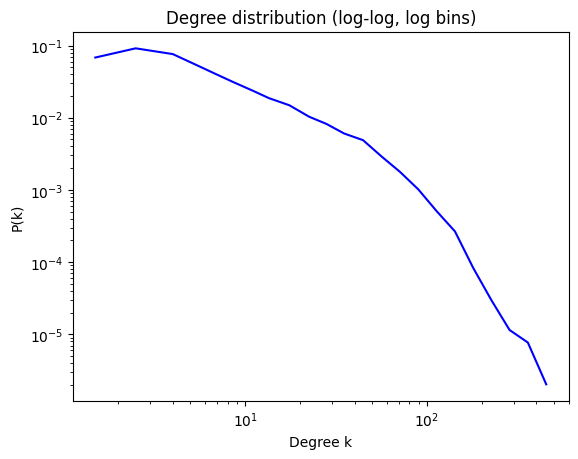

In [14]:
powerlaw.plot_pdf(deg, color="b")
plt.title("Degree distribution (log-log, log bins)")
plt.xlabel("Degree k"); plt.ylabel("P(k)"); plt.show()

In [15]:
fit = powerlaw.Fit(deg, discrete=True)
print(f"alpha = {fit.alpha:.3f} +/- {fit.sigma:.3f}")
print(f"xmin  = {fit.xmin}")
print(f"KS D  = {fit.D:.4f}")
print(f"Tail size: {(deg >= fit.xmin).sum()} of {len(deg)} nodes")

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 232/232 [00:01<00:00, 177.37it/s]

alpha = 2.865 +/- 0.033
xmin  = 39.0
KS D  = 0.0606
Tail size: 3186 of 18772 nodes


In [16]:
for alt in ["exponential", "lognormal", "truncated_power_law", "stretched_exponential"]:
    R, p = fit.distribution_compare("power_law", alt, normalized_ratio=True)
    print(f"power_law vs {alt:22s} R = {R:8.3f}, p = {p:.4f}")

power_law vs exponential            R =   -2.011, p = 0.0443
power_law vs lognormal              R =   -8.198, p = 0.0000
power_law vs truncated_power_law    R =   -8.046, p = 0.0000
power_law vs stretched_exponential  R =   -8.270, p = 0.0000


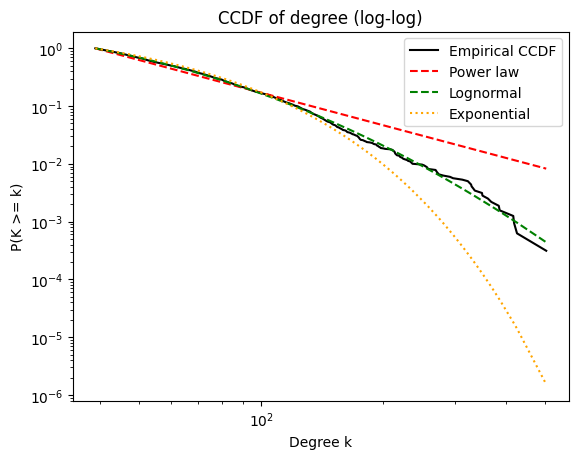

In [17]:
ax = fit.plot_ccdf(color="k", label="Empirical CCDF")
fit.power_law.plot_ccdf(ax=ax, color="r", linestyle="--", label="Power law")
fit.lognormal.plot_ccdf(ax=ax, color="g", linestyle="--", label="Lognormal")
fit.exponential.plot_ccdf(ax=ax, color="orange", linestyle=":", label="Exponential")
ax.set(title="CCDF of degree (log-log)", xlabel="Degree k", ylabel="P(K >= k)")
ax.legend(); plt.show()